# Estimating Population Parameters with Confidence Intervals: Bank Marketing Data

**Course:** AIT 530

**Assignment:** Statistical Inference — Point Estimates and Confidence Intervals

**By:** Yashu Lanki

## Table of Contents

1. Dataset Selection and Objectives
2. Point Estimates
3. Confidence Intervals
4. Estimation Procedures: How Sample Size Changes the Intervals
5. Formulating Inferences
6. Summary of Findings
7. References

## Part 1: Dataset Selection and Objectives

**Kaggle example.** Before choosing my own dataset, I reviewed Kaggle datasets and notebooks used to practice estimating population parameters. The code in these notebooks usually follows the same steps:
- It draws a **random sample** from a larger dataset and computes the **sample mean** and **sample proportion**.
- It builds a **95% confidence interval** using the standard error, with a *t* or *z* critical value from `scipy.stats`.
- It repeats the sampling with **different sample sizes** to show how the interval gets narrower as the sample grows.

I used the same approach in this report, but applied it to a dataset from a repository other than Kaggle, as the assignment requires.

**My dataset.** I used the **Bank Marketing Dataset** from the **UCI Machine Learning Repository** (Moro et al., 2014). It contains **45,211 clients** contacted by a Portuguese bank in phone marketing campaigns between May 2008 and November 2010. For each client, it records personal details (age, job, marital status, education, account balance) and whether the client **subscribed to a term deposit** after the campaign.

**Why this dataset?**
- It has **both numerical and categorical variables**, which the assignment requires. I used **age** (numerical) and **subscribed to a term deposit** (categorical: yes/no).
- It is **large**. Because I have all 45,211 clients, I can treat the full dataset as the **population** and draw smaller **samples** from it. That means I can check every estimate against the true population value, which is not possible in most real studies.
- It is **relevant to AI**. This dataset is widely used to train classification models that predict which clients will subscribe. Those models depend on how well a sample of data represents the population of customers.

**Objectives.**
1. Use one random sample to calculate **point estimates** of the population mean age and the population proportion of subscribers.
2. Build **95% confidence intervals** for both and interpret them.
3. Repeat the sampling with **different sample sizes** to see how sample size and variability change the intervals.
4. Draw **inferences** about the population and discuss the assumptions and limitations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

bank = pd.read_csv("bank_data/bank-full.csv", sep=";")
bank["subscribed"] = (bank["y"] == "yes").astype(int)   # 1 = yes, 0 = no

print(f"Rows: {bank.shape[0]:,}   Columns: {bank.shape[1]}   Missing values: {bank.isna().sum().sum()}")
print("Numerical columns:  ", list(bank.select_dtypes("number").columns.drop("subscribed")))
print("Categorical columns:", list(bank.select_dtypes(exclude="number").columns))
bank[["age", "job", "marital", "education", "balance", "y"]].head()

Rows: 45,211   Columns: 18   Missing values: 0
Numerical columns:   ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


,age,job,marital,education,balance,y
0,58,management,married,tertiary,2143,no
1,44,technician,single,secondary,29,no
2,33,entrepreneur,married,secondary,2,no
3,47,blue-collar,married,unknown,1506,no
4,33,unknown,single,unknown,1,no


**Population parameters (the "true" answers).** Since I have the full dataset, I first calculated the true population values. In a real study these would be **unknown**. They are only used later to check how well the sample estimates and intervals worked.

Population size N               = 45,211
Population mean age (μ)         = 40.94 years
Population variance of age (σ²) = 112.76   (σ = 10.62)
Population proportion subscribed (p) = 0.1170  (11.70%)


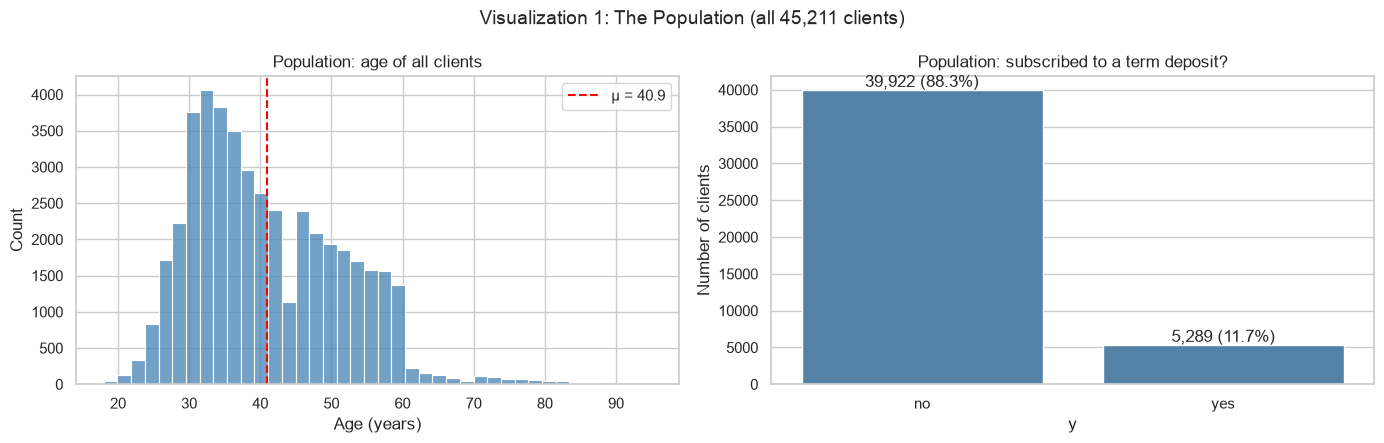

In [2]:
pop_mean_age = bank["age"].mean()
pop_sd_age = bank["age"].std(ddof=0)
pop_var_age = bank["age"].var(ddof=0)
pop_prop = bank["subscribed"].mean()
N = len(bank)

print(f"Population size N               = {N:,}")
print(f"Population mean age (μ)         = {pop_mean_age:.2f} years")
print(f"Population variance of age (σ²) = {pop_var_age:.2f}   (σ = {pop_sd_age:.2f})")
print(f"Population proportion subscribed (p) = {pop_prop:.4f}  ({pop_prop:.2%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(bank["age"], bins=40, ax=axes[0], color="steelblue")
axes[0].axvline(pop_mean_age, color="red", linestyle="--", label=f"μ = {pop_mean_age:.1f}")
axes[0].set_title("Population: age of all clients")
axes[0].set_xlabel("Age (years)")
axes[0].legend()
counts = bank["y"].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[1], color="steelblue")
for i, v in enumerate(counts.values):
    axes[1].text(i, v, f"{v:,} ({v / N:.1%})", ha="center", va="bottom")
axes[1].set_title("Population: subscribed to a term deposit?")
axes[1].set_ylabel("Number of clients")
fig.suptitle("Visualization 1: The Population (all 45,211 clients)", fontsize=14)
plt.tight_layout()
plt.show()

Age is **right-skewed**: most clients are between about 30 and 50, with a longer tail of older clients. Only about **11.7%** of clients subscribed, so the categorical variable is **imbalanced**.

## Part 2: Point Estimates

A **point estimate** is a single number calculated from a sample that serves as our best guess for an unknown population value:
- The **sample mean** $\bar{x} = \frac{1}{n}\sum x_i$ estimates the population mean **μ**.
- The **sample proportion** $\hat{p} = \frac{\text{number of successes}}{n}$ estimates the population proportion **p**.
- The **sample variance** $s^2 = \frac{1}{n-1}\sum (x_i - \bar{x})^2$ estimates the population variance **σ²**. Dividing by *n − 1* instead of *n* makes it an unbiased estimate.

I drew **one simple random sample of n = 500 clients** without replacement. This is the situation a real analyst would be in: one sample, and an unknown population.

In [3]:
n = 500
sample = bank.sample(n=n, random_state=42)

x_bar = sample["age"].mean()
s = sample["age"].std(ddof=1)
s2 = sample["age"].var(ddof=1)
p_hat = sample["subscribed"].mean()

point_estimates = pd.DataFrame({
    "point estimate (sample, n = 500)": [x_bar, s2, p_hat],
    "true population value": [pop_mean_age, pop_var_age, pop_prop],
}, index=["mean age (x̄ → μ)", "variance of age (s² → σ²)", "proportion subscribed (p̂ → p)"])
point_estimates["error"] = point_estimates.iloc[:, 0] - point_estimates.iloc[:, 1]
point_estimates

,"point estimate (sample, n = 500)",true population value,error
mean age (x̄ → μ),41.1340,40.9362,0.1978
variance of age (s² → σ²),105.8437,112.7556,-6.9119
proportion subscribed (p̂ → p),0.1320,0.1170,0.0150


**What these point estimates mean for the population.**
- **Mean age:** the sample mean is about **41.1 years**, so our best single guess is that the average client in the bank's whole customer list is about 41 years old. The true value is 40.9, so the sample was off by only about 0.2 years.
- **Proportion subscribed:** in the sample, **13.2%** of clients subscribed, so our best guess is that about 13% of all clients would subscribe. The true value is 11.7%, so this estimate is off by about 1.5 percentage points.
- **Variance of age:** the sample variance is about **105.8** (standard deviation ≈ 10.3 years), compared with the true 112.8. This tells us how spread out ages are in the population.

A point estimate is useful because it is a single, clear number. But on its own, it **does not say how close it is likely to be** to the truth. A different random sample of 500 clients would give a different mean, proportion, and variance. That is **sampling variation**, and it is why we also need confidence intervals.

## Part 3: Confidence Intervals

A **95% confidence interval (CI)** is a range of values built around a point estimate:

$$\text{point estimate} \pm \text{critical value} \times \text{standard error}$$

- The **standard error (SE)** measures how much the point estimate would change from sample to sample.
- The **critical value** sets the confidence level (about 1.96 for 95%).

**How to read it:** if we repeated the sampling process many times and built an interval each time, about **95% of those intervals would contain the true population value**. It does *not* mean there is a 95% chance that this one interval is right. The true value is fixed, and the interval either contains it or doesn't.

**Formulas used:**
- **Mean (t-interval):** $\bar{x} \pm t_{0.975,\,n-1} \cdot \dfrac{s}{\sqrt{n}}$. I used the *t* distribution because the population standard deviation is unknown and estimated by *s*.
- **Proportion (Wald / normal approximation):** $\hat{p} \pm z_{0.975} \cdot \sqrt{\dfrac{\hat{p}(1-\hat{p})}{n}}$. This works when there are at least about 10 successes and 10 failures in the sample. I also calculated the **Wilson interval**, which is more reliable for small samples and proportions near 0 or 1.

In [4]:
def mean_ci(x, conf=0.95):
    x = np.asarray(x)
    n = len(x)
    se = x.std(ddof=1) / np.sqrt(n)
    t_crit = stats.t.ppf((1 + conf) / 2, df=n - 1)
    return x.mean(), x.mean() - t_crit * se, x.mean() + t_crit * se, se

def prop_ci_wald(successes, n, conf=0.95):
    p = successes / n
    se = np.sqrt(p * (1 - p) / n)
    z = stats.norm.ppf((1 + conf) / 2)
    return p, p - z * se, p + z * se, se

def prop_ci_wilson(successes, n, conf=0.95):
    ci = stats.binomtest(int(successes), n).proportion_ci(confidence_level=conf, method="wilson")
    return ci.low, ci.high

m, m_lo, m_hi, m_se = mean_ci(sample["age"])
k = int(sample["subscribed"].sum())
p, p_lo, p_hi, p_se = prop_ci_wald(k, n)
w_lo, w_hi = prop_ci_wilson(k, n)

print(f"Successes = {k}, failures = {n - k}  (both ≥ 10, so the normal approximation is OK)\n")
ci_table = pd.DataFrame({
    "point estimate": [m, p, p],
    "standard error": [m_se, p_se, np.nan],
    "95% CI lower": [m_lo, p_lo, w_lo],
    "95% CI upper": [m_hi, p_hi, w_hi],
    "CI width": [m_hi - m_lo, p_hi - p_lo, w_hi - w_lo],
    "true value": [pop_mean_age, pop_prop, pop_prop],
}, index=["mean age (t-interval)", "proportion subscribed (Wald)", "proportion subscribed (Wilson)"])
ci_table["contains true value?"] = (ci_table["95% CI lower"] <= ci_table["true value"]) & (ci_table["true value"] <= ci_table["95% CI upper"])
ci_table

Successes = 66, failures = 434  (both ≥ 10, so the normal approximation is OK)



,point estimate,standard error,95% CI lower,95% CI upper,CI width,true value,contains true value?
mean age (t-interval),41.1340,0.4601,40.2300,42.0380,1.8079,40.9362,True
proportion subscribed (Wald),0.1320,0.0151,0.1023,0.1617,0.0593,0.1170,True
proportion subscribed (Wilson),0.1320,NaN,0.1051,0.1645,0.0594,0.1170,True


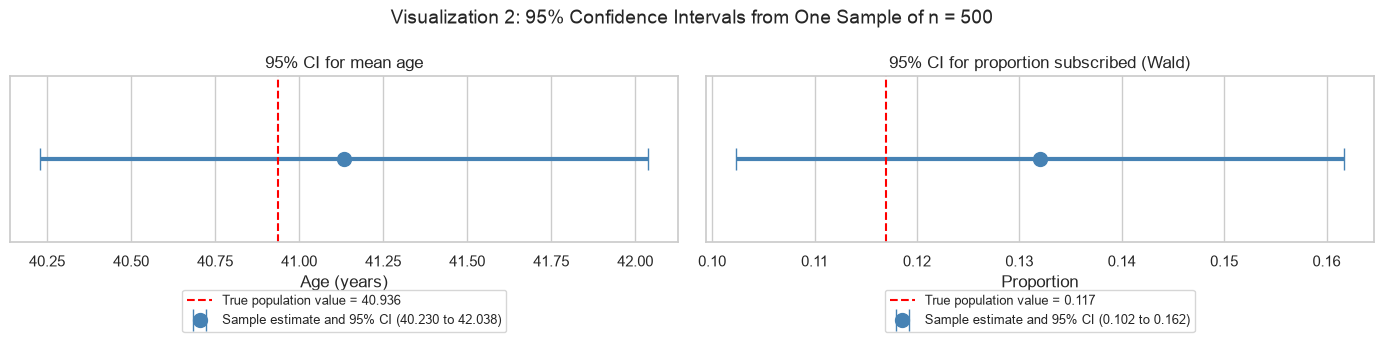

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (est, lo, hi, true, title, unit) in zip(axes, [
        (m, m_lo, m_hi, pop_mean_age, "95% CI for mean age", "Age (years)"),
        (p, p_lo, p_hi, pop_prop, "95% CI for proportion subscribed (Wald)", "Proportion")]):
    ax.errorbar(est, 0, xerr=[[est - lo], [hi - est]], fmt="o", color="steelblue", capsize=8, lw=3, ms=10,
                label=f"Sample estimate and 95% CI ({lo:.3f} to {hi:.3f})")
    ax.axvline(true, color="red", linestyle="--", label=f"True population value = {true:.3f}")
    ax.set_yticks([])
    ax.set_xlabel(unit)
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), fontsize=9)
fig.suptitle("Visualization 2: 95% Confidence Intervals from One Sample of n = 500", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation.**
- **Mean age:** we are 95% confident that the **average age of all clients is between about 40.2 and 42.0 years**. The interval is only about 1.8 years wide, so the estimate is quite precise. The true mean (40.9) is inside the interval.
- **Proportion subscribed:** we are 95% confident that **between about 10.2% and 16.2% of all clients would subscribe** to a term deposit. The true proportion (11.7%) is inside. The Wilson interval (about 10.5% to 16.5%) is very close to the Wald interval here because the sample is large enough.

**What can we infer about the population?** Even without seeing the full dataset, the sample tells us that the typical client is in their early 40s and that subscribers are a **small minority**: almost certainly fewer than 1 in 6 clients. For the bank, this means most calls in a campaign will not lead to a sale.

**How sample size and variability affect the width.** Both standard errors have the form $\frac{\text{variability}}{\sqrt{n}}$:
- A **larger sample size (*n*)** makes the standard error smaller, so the interval gets **narrower**. Because of the square root, you need **4 times as many** observations to cut the width in **half**.
- **More variability** in the data (a larger *s*, or a proportion closer to 50%) makes the standard error bigger, so the interval gets **wider**. Ages vary a lot (s ≈ 10.3 years), which is why the interval is not even narrower.

## Part 4: Estimation Procedures — How Sample Size Changes the Intervals

To see how sample size affects the confidence intervals, I took **new random samples of five different sizes**: n = 30, 100, 500, 1,000, and 5,000. For each one, I recalculated the point estimates and the 95% confidence intervals.

In [6]:
sizes = [30, 100, 500, 1000, 5000]
rows = []
for i, size in enumerate(sizes):
    smp = bank.sample(n=size, random_state=100 + i)
    mm, mlo, mhi, _ = mean_ci(smp["age"])
    kk = int(smp["subscribed"].sum())
    pp, plo, phi, _ = prop_ci_wald(kk, size)
    rows.append({"n": size, "mean age": mm, "age CI lower": mlo, "age CI upper": mhi, "age CI width": mhi - mlo,
                 "variance of age": smp["age"].var(ddof=1),
                 "p̂": pp, "p CI lower": plo, "p CI upper": phi, "p CI width": phi - plo})
by_size = pd.DataFrame(rows).set_index("n")
by_size

,mean age,age CI lower,age CI upper,age CI width,variance of age,p̂,p CI lower,p CI upper,p CI width
n,,,,,,,,,
30,36.8333,33.3044,40.3623,7.0579,89.3161,0.0333,-0.0309,0.0976,0.1285
100,39.4200,37.6210,41.2190,3.5981,82.2057,0.0800,0.0268,0.1332,0.1063
500,41.2120,40.2630,42.1610,1.8981,116.6644,0.1180,0.0897,0.1463,0.0566
1000,41.1220,40.4727,41.7713,1.2986,109.4846,0.1230,0.1026,0.1434,0.0407
5000,40.9058,40.6162,41.1954,0.5792,109.0939,0.1190,0.1100,0.1280,0.0179


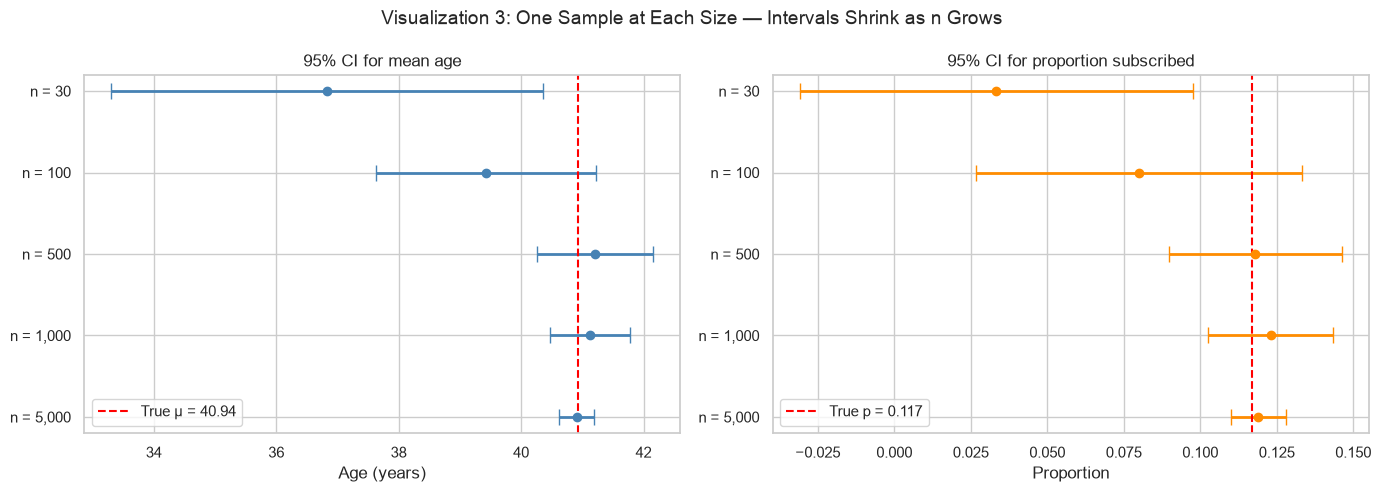

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ypos = np.arange(len(sizes))
axes[0].errorbar(by_size["mean age"], ypos,
                 xerr=[by_size["mean age"] - by_size["age CI lower"], by_size["age CI upper"] - by_size["mean age"]],
                 fmt="o", color="steelblue", capsize=6, lw=2)
axes[0].axvline(pop_mean_age, color="red", linestyle="--", label=f"True μ = {pop_mean_age:.2f}")
axes[0].set_title("95% CI for mean age")
axes[0].set_xlabel("Age (years)")

axes[1].errorbar(by_size["p̂"], ypos,
                 xerr=[by_size["p̂"] - by_size["p CI lower"], by_size["p CI upper"] - by_size["p̂"]],
                 fmt="o", color="darkorange", capsize=6, lw=2)
axes[1].axvline(pop_prop, color="red", linestyle="--", label=f"True p = {pop_prop:.3f}")
axes[1].set_title("95% CI for proportion subscribed")
axes[1].set_xlabel("Proportion")

for ax in axes:
    ax.set_yticks(ypos)
    ax.set_yticklabels([f"n = {s:,}" for s in sizes])
    ax.invert_yaxis()
    ax.legend()
fig.suptitle("Visualization 3: One Sample at Each Size — Intervals Shrink as n Grows", fontsize=14)
plt.tight_layout()
plt.show()

**What one sample per size shows.** The intervals clearly get narrower as *n* grows: the age interval is about 7 years wide at n = 30 but only about 0.6 years at n = 5,000. The small samples also show two warning signs:
- The **n = 30 age interval (33.3 to 40.4) misses the true mean** of 40.9. With a 95% CI, about 1 in 20 intervals will miss, and small samples are where large misses happen.
- The **n = 30 proportion interval goes below zero** (−3.1% to 9.8%). Only 1 of the 30 clients subscribed, so the normal approximation breaks down and gives an impossible range.

One sample per size shows the trend, but each sample is partly luck. To measure the effect properly, I repeated the process **1,000 times for each sample size** and recorded:
- the **average CI width** (precision), and
- the **coverage**: the share of the 1,000 intervals that contained the true population value (accuracy). For a 95% CI, coverage should be close to 95%.

In [8]:
rng = np.random.default_rng(42)
reps = 1000
ages = bank["age"].values
subs = bank["subscribed"].values

sim_rows, mean_draws, var_draws = [], {}, {}
for size in sizes:
    idx = np.array([rng.choice(N, size=size, replace=False) for _ in range(reps)])
    A, S = ages[idx], subs[idx]

    means = A.mean(axis=1)
    sds = A.std(axis=1, ddof=1)
    t_crit = stats.t.ppf(0.975, df=size - 1)
    m_half = t_crit * sds / np.sqrt(size)

    props = S.mean(axis=1)
    p_half = 1.96 * np.sqrt(props * (1 - props) / size)
    wilson = [stats.binomtest(int(k), size).proportion_ci(method="wilson") for k in S.sum(axis=1)]
    w_low = np.array([w.low for w in wilson])
    w_high = np.array([w.high for w in wilson])

    mean_draws[size], var_draws[size] = means, sds ** 2
    sim_rows.append({
        "n": size,
        "avg age CI width": (2 * m_half).mean(),
        "age CI coverage": ((means - m_half <= pop_mean_age) & (pop_mean_age <= means + m_half)).mean(),
        "SD of sample means": means.std(ddof=1),
        "SD of sample variances": (sds ** 2).std(ddof=1),
        "avg p CI width (Wald)": (2 * p_half).mean(),
        "p CI coverage (Wald)": ((props - p_half <= pop_prop) & (pop_prop <= props + p_half)).mean(),
        "p CI coverage (Wilson)": ((w_low <= pop_prop) & (pop_prop <= w_high)).mean(),
        "samples with p̂ = 0": (props == 0).mean(),
    })

sim = pd.DataFrame(sim_rows).set_index("n")
sim

,avg age CI width,age CI coverage,SD of sample means,SD of sample variances,avg p CI width (Wald),p CI coverage (Wald),p CI coverage (Wilson),samples with p̂ = 0
n,,,,,,,,
30,7.8496,0.9390,2.0033,30.7425,0.2168,0.8660,0.9210,0.0270
100,4.2183,0.9470,1.0859,16.9195,0.1237,0.9450,0.9460,0.0000
500,1.8648,0.9500,0.4791,8.0607,0.0562,0.9610,0.9580,0.0000
1000,1.3178,0.9680,0.3292,5.3810,0.0398,0.9460,0.9410,0.0000
5000,0.5887,0.9690,0.1358,2.2287,0.0178,0.9590,0.9590,0.0000


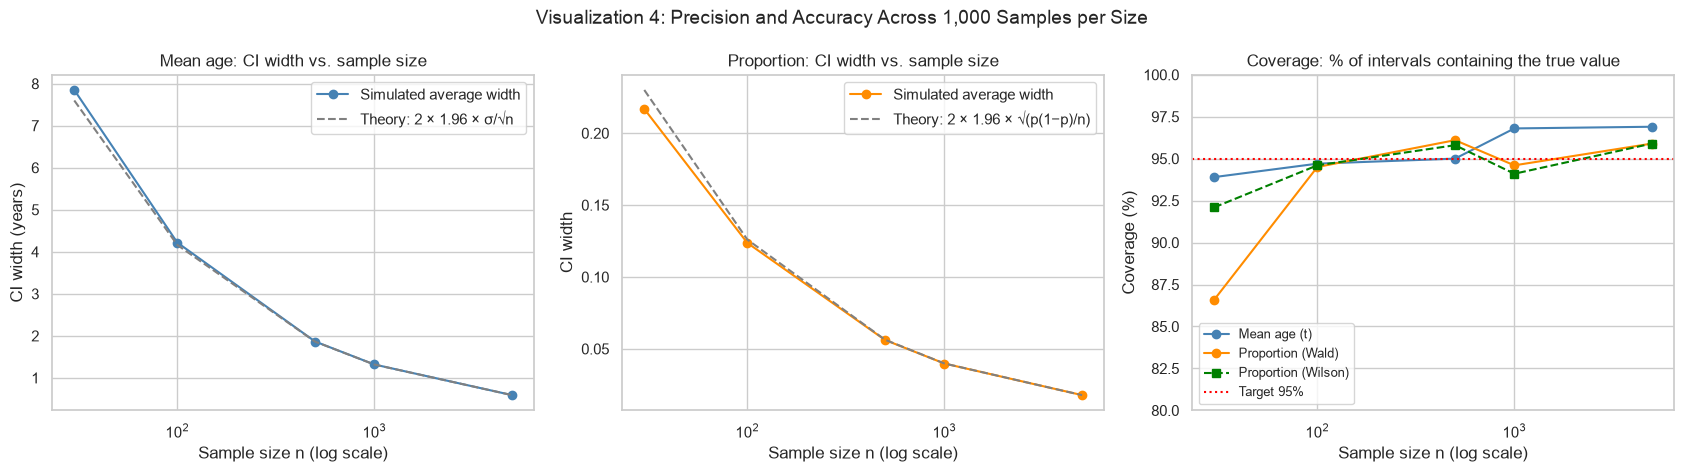

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ns = np.array(sizes)

axes[0].plot(ns, sim["avg age CI width"], "o-", color="steelblue", label="Simulated average width")
axes[0].plot(ns, 2 * 1.96 * pop_sd_age / np.sqrt(ns), "--", color="gray", label="Theory: 2 × 1.96 × σ/√n")
axes[0].set_xscale("log")
axes[0].set_title("Mean age: CI width vs. sample size")
axes[0].set_xlabel("Sample size n (log scale)")
axes[0].set_ylabel("CI width (years)")
axes[0].legend()

axes[1].plot(ns, sim["avg p CI width (Wald)"], "o-", color="darkorange", label="Simulated average width")
axes[1].plot(ns, 2 * 1.96 * np.sqrt(pop_prop * (1 - pop_prop) / ns), "--", color="gray", label="Theory: 2 × 1.96 × √(p(1−p)/n)")
axes[1].set_xscale("log")
axes[1].set_title("Proportion: CI width vs. sample size")
axes[1].set_xlabel("Sample size n (log scale)")
axes[1].set_ylabel("CI width")
axes[1].legend()

axes[2].plot(ns, sim["age CI coverage"] * 100, "o-", color="steelblue", label="Mean age (t)")
axes[2].plot(ns, sim["p CI coverage (Wald)"] * 100, "o-", color="darkorange", label="Proportion (Wald)")
axes[2].plot(ns, sim["p CI coverage (Wilson)"] * 100, "s--", color="green", label="Proportion (Wilson)")
axes[2].axhline(95, color="red", linestyle=":", label="Target 95%")
axes[2].set_xscale("log")
axes[2].set_ylim(80, 100)
axes[2].set_title("Coverage: % of intervals containing the true value")
axes[2].set_xlabel("Sample size n (log scale)")
axes[2].set_ylabel("Coverage (%)")
axes[2].legend(fontsize=9)

fig.suptitle("Visualization 4: Precision and Accuracy Across 1,000 Samples per Size", fontsize=14)
plt.tight_layout()
plt.show()

**Sampling variation of the estimates themselves.** The assignment focuses on how the *estimated values* change from sample to sample. The histograms below show the 1,000 sample means and 1,000 sample variances for a small sample (n = 30) and a large sample (n = 1,000).

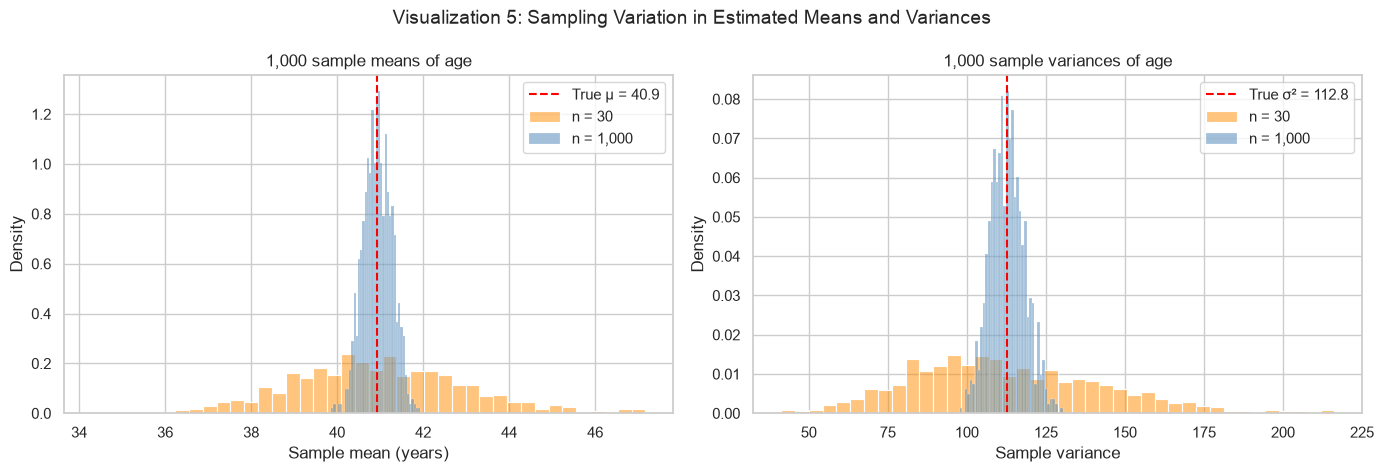

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for size, color in [(30, "darkorange"), (1000, "steelblue")]:
    sns.histplot(mean_draws[size], bins=40, stat="density", ax=axes[0], color=color, alpha=0.5, label=f"n = {size:,}")
    sns.histplot(var_draws[size], bins=40, stat="density", ax=axes[1], color=color, alpha=0.5, label=f"n = {size:,}")
axes[0].axvline(pop_mean_age, color="red", linestyle="--", label=f"True μ = {pop_mean_age:.1f}")
axes[0].set_title("1,000 sample means of age")
axes[0].set_xlabel("Sample mean (years)")
axes[1].axvline(pop_var_age, color="red", linestyle="--", label=f"True σ² = {pop_var_age:.1f}")
axes[1].set_title("1,000 sample variances of age")
axes[1].set_xlabel("Sample variance")
for ax in axes:
    ax.legend()
fig.suptitle("Visualization 5: Sampling Variation in Estimated Means and Variances", fontsize=14)
plt.tight_layout()
plt.show()

**Discussion: how the intervals change with sample size.**
- **Precision improves with *n*.** The average CI width for mean age drops from about **7.8 years at n = 30** to **1.9 years at n = 500** and **0.6 years at n = 5,000**. The proportion CI drops from about **22 percentage points** wide to under **2**. The simulated widths follow the theoretical $1/\sqrt{n}$ curve almost exactly. Going from 500 to 5,000 (10× the data) only made the interval about **3× narrower** ($\sqrt{10} \approx 3.2$), so there are diminishing returns.
- **Accuracy (coverage) depends on whether the method's assumptions hold.** The *t*-interval for mean age stayed **close to 95% coverage at every sample size** (between about 94% and 97%), even at n = 30, because the CLT makes the sample mean close to normal even though age is skewed. The Wald interval for the proportion was **too optimistic at n = 30**: only about **87%** of intervals contained the truth, and about 3% of samples had *no* subscribers at all, which gives a meaningless interval of width 0. That happens because with p ≈ 0.117, a sample of 30 has only about 3.5 expected subscribers, well below the "at least 10 successes" rule. The **Wilson interval** fixes much of this problem (about 92% coverage at n = 30). From n = 100 upward, both methods were close to 95%.
- **The estimates themselves vary less with larger samples.** In Visualization 5, the sample means and sample variances from n = 30 are spread widely, while those from n = 1,000 are tightly clustered around the true values. The sample variance is especially unstable in small samples: its standard deviation across samples falls from about 31 at n = 30 to about 5 at n = 1,000. This happens because age is skewed, so a few older clients can change the variance a lot.
- **Bigger samples don't fix bias.** A larger random sample makes estimates more *precise*, but if the sample were not random (for example, only clients called in May), more data would just make us more confident in the wrong answer.

## Part 5: Formulating Inferences

**Inference about the population parameters.** Based on one random sample of 500 clients:
- The **average age** of the bank's clients is estimated at **41.1 years**, and we are 95% confident it is **between 40.2 and 42.0 years**.
- The **proportion of clients who subscribe** to a term deposit is estimated at **13.2%**, and we are 95% confident it is **between 10.2% and 16.2%**.

Both intervals contain the true population values (40.9 years and 11.7%), and the repeated-sampling study confirmed that this method captures the truth about 95% of the time once the sample is large enough.

**A professional argument.** A sample of 500 clients is enough to make sound business decisions about this population. It pins down the average client age to within about ±1 year, and it shows with high confidence that **at most about 1 in 6 contacted clients subscribes**. The bank should therefore plan campaigns expecting a **low success rate**. That makes it worth using a predictive model to target the clients most likely to say yes, instead of calling everyone. If the bank needed a tighter estimate of the subscription rate (for example, ±1 percentage point to forecast revenue), the analysis shows exactly how to get it: a sample of a few thousand clients.

**Assumptions and their limitations.**

| Assumption | Does it hold here? | Limitation |
|---|---|---|
| **Random sampling** | Yes. The samples were drawn at random from the full dataset. | The dataset itself is not a random sample of *all* bank customers. It only includes clients who were *called* in 2008–2010 campaigns, so the results may not generalize to other banks, countries, or years. |
| **Independence** | Approximately. Each sample is less than 10% of the 45,211 clients (except n = 5,000 at 11%). | Some clients were contacted multiple times, which could create small dependencies. |
| **Approximate normality of the estimate (CLT)** | Yes for n ≥ 30 for the mean. Yes for the proportion when there are at least 10 successes and 10 failures. | For small samples and rare outcomes (n = 30, p ≈ 0.12), the Wald interval is unreliable. The Wilson interval should be used instead. |
| **Data quality** | No missing values. | Some categories use "unknown" as a value. The data reflects one bank during a financial crisis period, which may affect subscription rates. |

**Why sample size, variability, and robustness matter in AI.**
- **Training data:** a model learns patterns from a sample of the population. With a small sample, the model's learned patterns vary a lot from sample to sample (just like the sample means at n = 30), so it is more likely to overfit and perform poorly on new data.
- **Rare classes:** subscribers are only about 12% of clients. In a small training set, there may be too few positive examples to learn from, just as some n = 30 samples had zero subscribers. This is why techniques like stratified sampling and class weighting are used.
- **Evaluating models:** a model's accuracy on a test set is itself a **sample proportion**. A test set of 100 examples gives an accuracy estimate with a margin of error of about ±6 percentage points. Two models that differ by 2 points may not really be different. Reporting accuracy with a confidence interval makes model comparisons honest.
- **Robustness:** estimates that rely on assumptions that don't hold (like the Wald interval for a rare outcome in a small sample) can look precise while being wrong. Checking assumptions, or using more robust methods like the Wilson interval or bootstrapping, keeps AI systems trustworthy.

## Part 6: Summary of Findings

| Analysis | Key finding |
|---|---|
| Point estimates (n = 500) | Mean age x̄ ≈ 41.1 years (true 40.9). Proportion subscribed p̂ = 13.2% (true 11.7%). Variance of age s² ≈ 105.8 (true 112.8). |
| 95% CI for mean age | About 40.2 to 42.0 years. Contains the true mean. |
| 95% CI for proportion | About 10.2% to 16.2% (Wald), 10.5% to 16.5% (Wilson). Contains the true proportion. |
| Effect of sample size | CI width shrinks with 1/√n: from about 7.8 years (n = 30) to 0.6 years (n = 5,000) for the mean, and from about 22 to under 2 percentage points for the proportion. |
| Accuracy (coverage) | The *t*-interval for the mean stays near 95% for all sizes. The Wald interval for the proportion drops to about 87% at n = 30. Wilson does better (about 92%). |
| Inference | The typical client is in their early 40s, and subscribers are a small minority (at most about 1 in 6). |

**Performance analysis.** Because the full population was available, every estimate could be checked against the truth. The point estimates from n = 500 were close to the true values, and both 95% intervals contained them. The repeated-sampling study showed the methods performed as designed: the mean interval was accurate at every size, and its width followed the $1/\sqrt{n}$ rule. The one weakness was the Wald proportion interval with small samples and a rare outcome, where coverage fell below 95%. This shows why it is important to check assumptions before trusting an interval.

## Part 7: References

Agresti, A., & Coull, B. A. (1998). Approximate is better than "exact" for interval estimation of binomial proportions. *The American Statistician, 52*(2), 119–126. https://doi.org/10.1080/00031305.1998.10480550

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001

Moro, S., Rita, P., & Cortez, P. (2014). *Bank marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953